In [1]:
from typing import Annotated, TypedDict
import operator

from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

In [2]:
def show_graph(compiled_graph, *, xray=False):
    """Print the generated graph as Mermaid text."""

    print(
        compiled_graph.get_graph(
            xray=xray
        ).draw_mermaid()
    )


In [3]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()

model = ChatOpenAI(
    model="gpt-4.1-mini",
    temperature=0,
)

ModuleNotFoundError: No module named 'dotenv'

In [4]:
class ParentState(TypedDict):
    topics: list[str]
    research_results: Annotated[
        list[str],
        operator.add,
    ]
    final_answer: str

In [5]:
class ResearchWorkerInput(TypedDict):
    topic: str

In [6]:
class ResearchState(TypedDict):
    topic: str
    research: str
    summary: str


### 2.2 Research subgraph nodes

In [7]:
def research_topic(state: ResearchState):
    topic = state["topic"]
    print(f"[SUBGRAPH] Researching: {topic}")

    response = model.invoke(
        f"""
Explain this Generative AI topic: {topic}

Include:
1. A definition
2. Important concepts
3. One practical use case

Keep the explanation concise.
"""
    )

    return {
        "research": response.content
    }

In [8]:
def summarize_topic(state: ResearchState):
    print(f"[SUBGRAPH] Summarizing: {state['topic']}")

    response = model.invoke(
        f"""
Create a concise summary of this research.

Topic: {state['topic']}

Research:
{state['research']}
"""
    )

    return {
        "summary": response.content
    }

### 2.3 Build the research subgraph

In [9]:
from typing import Annotated, TypedDict
import operator

from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

In [10]:
class ResearchState(TypedDict):
    topic: str
    research: str
    summary: str

In [11]:
research_builder = StateGraph(ResearchState)

In [12]:
research_builder.add_node(
    "research_topic",
    research_topic,
)

research_builder.add_node(
    "summarize_topic",
    summarize_topic,
)

In [13]:
research_builder.add_edge(
    START,
    "research_topic",
)

research_builder.add_edge(
    "research_topic",
    "summarize_topic",
)

research_builder.add_edge(
    "summarize_topic",
    END,
)

In [14]:
research_subgraph = research_builder.compile()

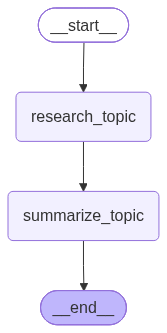

In [15]:
research_subgraph

### 2.4 Parent graph nodes

In [16]:
def prepare_topics(state: ParentState):
    print("Topics received:")

    for topic in state["topics"]:
        print(f"- {topic}")

    return {}

In [17]:
def distribute_topics(state: ParentState):
    return [
        Send("research_worker", {"topic": topic})
        for topic in state["topics"]
    ]


In [18]:
def research_worker(state: ResearchWorkerInput):
    topic = state["topic"]
    print(f"[WORKER] Starting: {topic}")

    subgraph_result = research_subgraph.invoke(
        {
            "topic": topic,
            "research": "",
            "summary": "",
        }
    )

    return {
        "research_results": [
            f"## {topic}\n\n{subgraph_result['summary']}"
        ]
    }

In [19]:
def combine_results(state: ParentState):
    combined_research = "\n\n".join(
        state["research_results"]
    )

    response = model.invoke(
        f"""
Combine these research summaries into one clear explanation.
Keep each topic under its own heading.

{combined_research}
"""
    )

    return {
        "final_answer": response.content
    }


In [20]:
class ParentState(TypedDict):
    topics: list[str]
    research_results: Annotated[
        list[str],
        operator.add,
    ]
    final_answer: str

In [21]:
research_parent_builder = StateGraph(ParentState)

In [22]:
research_parent_builder.add_node(
    "prepare_topics",
    prepare_topics,
)

research_parent_builder.add_node(
    "research_worker",
    research_worker,
)

research_parent_builder.add_node(
    "combine_results",
    combine_results,
)

In [24]:
research_parent_builder.add_edge(
    START,
    "prepare_topics",
)

research_parent_builder.add_conditional_edges(
    source="prepare_topics",
    path=distribute_topics,
    path_map=["research_worker"],
)

research_parent_builder.add_edge(
    "research_worker",
    "combine_results",
)

research_parent_builder.add_edge(
    "combine_results",
    END,
)

ValueError: Branch with name `distribute_topics` already exists for node `prepare_topics`

In [25]:
research_graph = research_parent_builder.compile()

In [26]:
print("RESEARCH SUBGRAPH")
show_graph(research_subgraph)

RESEARCH SUBGRAPH
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	research_topic(research_topic)
	summarize_topic(summarize_topic)
	__end__([<p>__end__</p>]):::last
	__start__ --> research_topic;
	research_topic --> summarize_topic;
	summarize_topic --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [27]:
print("PARENT GRAPH")
show_graph(research_graph)

PARENT GRAPH
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	prepare_topics(prepare_topics)
	research_worker(research_worker)
	combine_results(combine_results)
	__end__([<p>__end__</p>]):::last
	__start__ --> prepare_topics;
	prepare_topics -.-> research_worker;
	research_worker --> combine_results;
	combine_results --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

